In [7]:
import numpy as np
import cv2
import matplotlib.pyplot as plt
from skimage import data, filters, measure, morphology
from scipy import ndimage as ndi

In [2]:
def comparar_imagens(images, title, cmap='gray', size=4):
  n = len(images)
  plt.figure(figsize=(size*n, size))
  for i in range(n):
    plt.subplot(1, n, i + 1)
    plt.imshow(images[i], cmap=cmap)
    plt.title(title[i])
    plt.axis('off')
  plt.show()

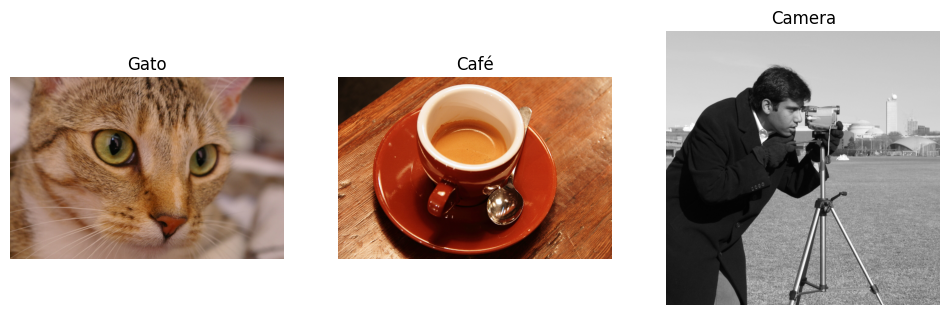

In [4]:
gato = data.cat()
cafe = data.coffee()
camera = data.camera()

comparar_imagens([gato, cafe, camera], ['Gato', 'Café', 'Camera'])

In [11]:
def plotar_comparacao_segmentacao(img, img_name="Imagem", invert=False, min_size=30):
    if img.ndim == 3:
        img_gray = cv2.cvtColor(img, cv2.COLOR_RGB2GRAY)
    else:
        img_gray = img.copy()

    limiar = filters.threshold_otsu(img_gray)
    if invert:
        semantic_mask = img_gray < limiar
    else:
        semantic_mask = img_gray > limiar

    semantic_mask = morphology.remove_small_objects(semantic_mask, min_size=min_size)
    semantic_mask = ndi.binary_fill_holes(semantic_mask)

    instance_mask, instance_num = measure.label(semantic_mask, return_num=True)

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    axes[0].imshow(img_gray, cmap='gray')
    axes[0].set_title(f'{img_name} (Original)')
    axes[0].axis('off')

    axes[1].imshow(semantic_mask, cmap='gray')
    axes[1].set_title(f'Segmentação Semântica (Otsu = {limiar:.0f})')
    axes[1].axis('off')

    axes[2].imshow(instance_mask, cmap='nipy_spectral')
    axes[2].set_title(f'Segmentação por Instância ({instance_num} objetos)')
    axes[2].axis('off')

    plt.tight_layout()
    plt.show()

    return semantic_mask, instance_mask, instance_num

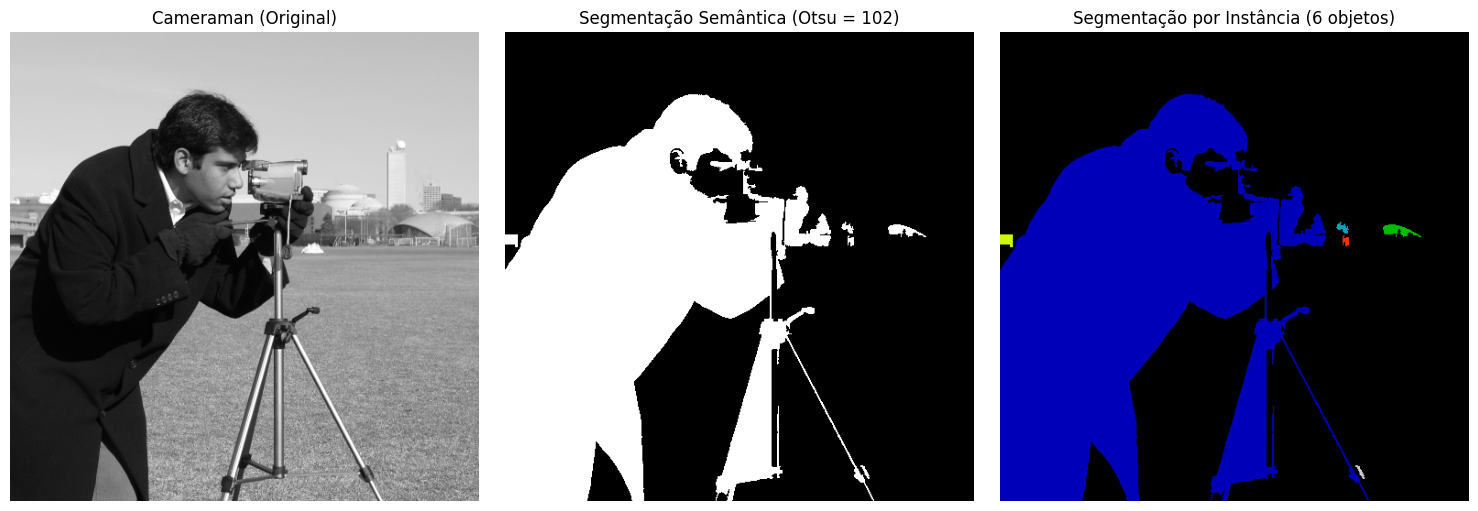

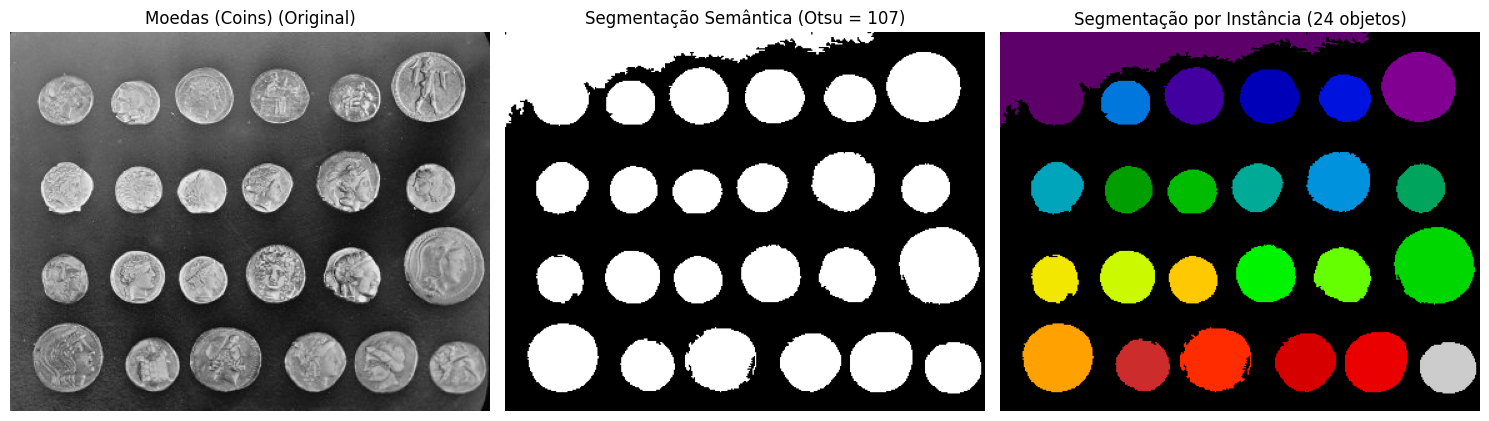

In [12]:
sem_cam, inst_cam, n_cam = plotar_comparacao_segmentacao(
    camera,
    img_name="Cameraman",
    invert=True,
    min_size=50
)

moedas = data.coins()
sem_moedas, inst_moedas, n_moedas = plotar_comparacao_segmentacao(
    moedas,
    img_name="Moedas (Coins)",
    invert=False,
    min_size=50
)

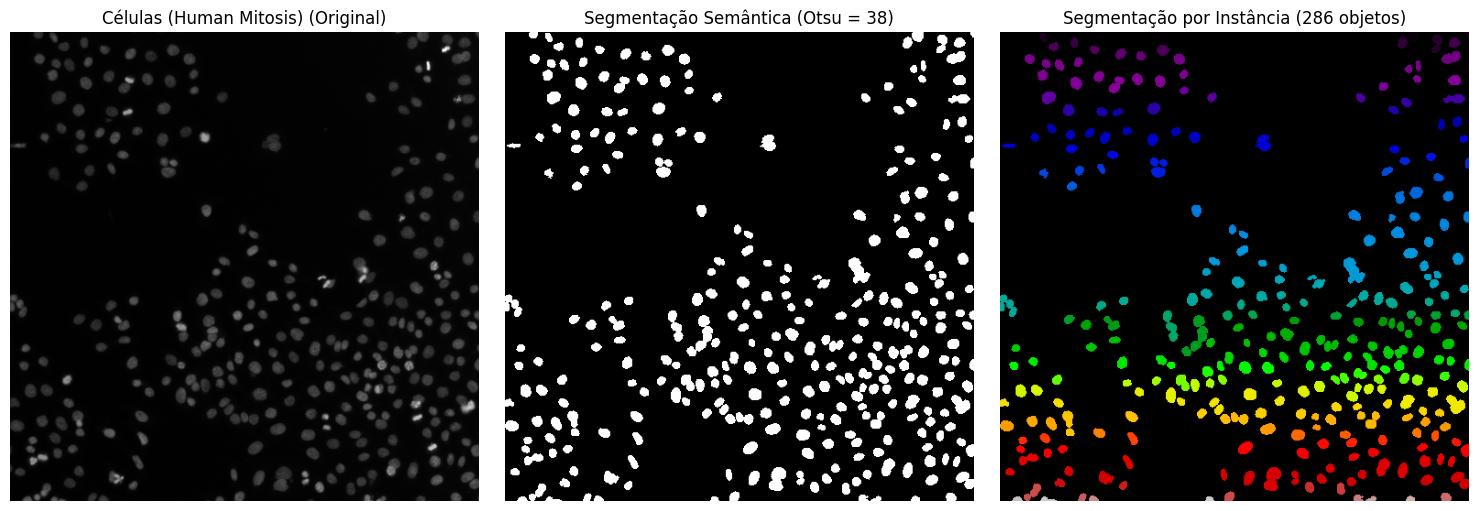

In [14]:
celulas = data.human_mitosis()

sem_cel, inst_cel, n_cel = plotar_comparacao_segmentacao(
    celulas,
    img_name="Células (Human Mitosis)",
    invert=False,
    min_size=15
)

### Análise Comparativa da Segmentação

1. **Diferença entre Segmentação Semântica e por Instância:**
   * Na Segmentação Semântica, todos os pixels que tem a classe de interesse recebem o mesmo valor binário (branco), tratando múltiplos objetos como uma única massa.
   * Na Segmentação por Instância, o algoritmo de componentes conectados identifica cada região isolada e atribui um identificador numérico e uma cor exclusiva para cada objeto.

2. **Diferença de resultado entre as imagens testadas (`Cameraman`/`Coins` vs. `Human Mitosis`):**
   * Na imagem do Cameraman (e nas bordas de Coins), o fundo possui texturas e gradientes de iluminação que possuem intensidades de cinza próximas as do objeto principal.
   * Já na imagem Human Mitosis, o fundo é escuro e homogêneo, proporcionando alto contraste com as células brilhantes.